# Lab 02 — PDF Analysis, Steganography and Compressive Sensing

This notebook works with Copernicus Browser exports of **Sentinel-2** (optical) and **Sentinel-1** (SAR) scenes over:
- **Urban**: Main Market Square, Kraków (`s2_urban.png`, `s1_urban.png`)
- **Natural**: Niepołomice Forest (`s2_forest.png`, `s1_forest.png`)

Tasks:
1. Compare probability density functions (histograms) of S2 / S1 for both terrains
2. Hide random data in the two least significant bits (LSB steganography) and check detectability
3. Run a small compressive-sensing demo and discuss its role in Earth Observation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import optimize, fftpack

%matplotlib inline
np.random.seed(0)

In [2]:
def load_rgb(path):
    """Load an image as uint8 RGB (drop alpha if present)."""
    img = np.array(Image.open(path).convert('RGB'))
    return img


def plot_channel_pdfs(images, titles, colors=('tab:red', 'tab:green', 'tab:blue')):
    """Plot per-channel histograms (density=True → approximate PDF) for several images."""
    n = len(images)
    fig, axes = plt.subplots(n, 3, figsize=(12, 2.8 * n), sharex=True)
    if n == 1:
        axes = np.array([axes])

    channel_names = ('R', 'G', 'B')
    for row, (img, title) in enumerate(zip(images, titles)):
        for c in range(3):
            ax = axes[row, c]
            ax.hist(img[:, :, c].ravel(), bins=64, density=True,
                    color=colors[c], alpha=0.85, edgecolor='none')
            ax.set_title(f'{title} — {channel_names[c]}')
            ax.set_xlabel('Digital number')
            ax.set_ylabel('PDF')
            ax.grid(True, alpha=0.25)

    plt.tight_layout()
    plt.show()

## 1. Probability Distribution Functions of Sentinel Data

We load at least three bands (RGB) for urban and natural areas from Sentinel-2, then repeat the same for Sentinel-1 false-colour exports of the same regions.

S2 urban : (1080, 1470, 3) uint8
S2 forest: (1080, 1470, 3) uint8
S1 urban : (1079, 1470, 3) uint8
S1 forest: (1079, 1470, 3) uint8


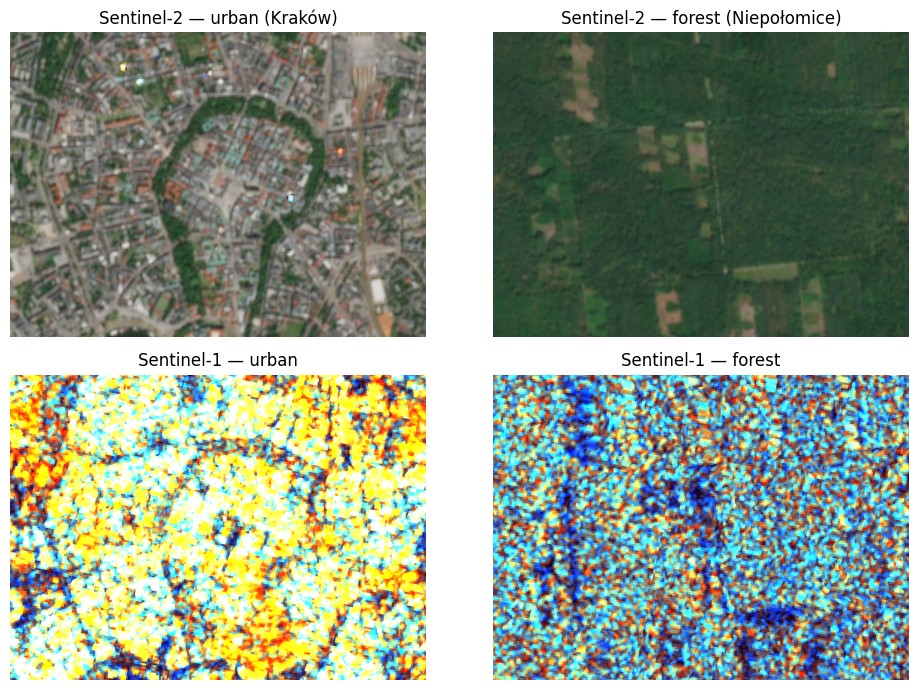

In [3]:
s2_urban = load_rgb('s2_urban.png')
s2_forest = load_rgb('s2_forest.png')
s1_urban = load_rgb('s1_urban.png')
s1_forest = load_rgb('s1_forest.png')

print('S2 urban :', s2_urban.shape, s2_urban.dtype)
print('S2 forest:', s2_forest.shape, s2_forest.dtype)
print('S1 urban :', s1_urban.shape, s1_urban.dtype)
print('S1 forest:', s1_forest.shape, s1_forest.dtype)

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes[0, 0].imshow(s2_urban);  axes[0, 0].set_title('Sentinel-2 — urban (Kraków)')
axes[0, 1].imshow(s2_forest); axes[0, 1].set_title('Sentinel-2 — forest (Niepołomice)')
axes[1, 0].imshow(s1_urban);  axes[1, 0].set_title('Sentinel-1 — urban')
axes[1, 1].imshow(s1_forest); axes[1, 1].set_title('Sentinel-1 — forest')
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

### Sentinel-2 histograms (optical RGB)

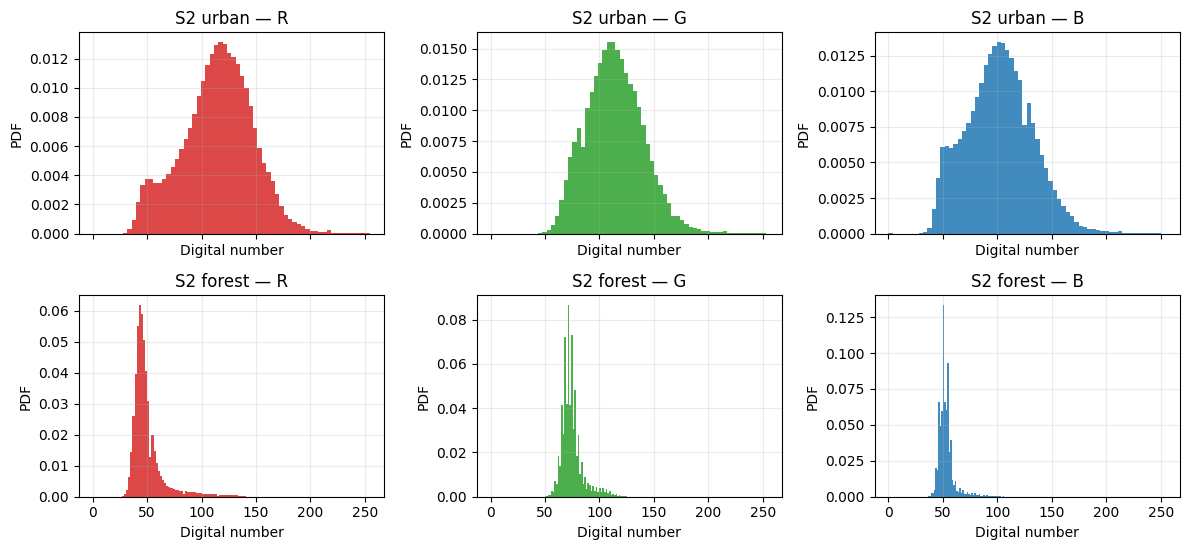

In [4]:
plot_channel_pdfs(
    [s2_urban, s2_forest],
    ['S2 urban', 'S2 forest']
)

### Sentinel-1 histograms (SAR visualisation)

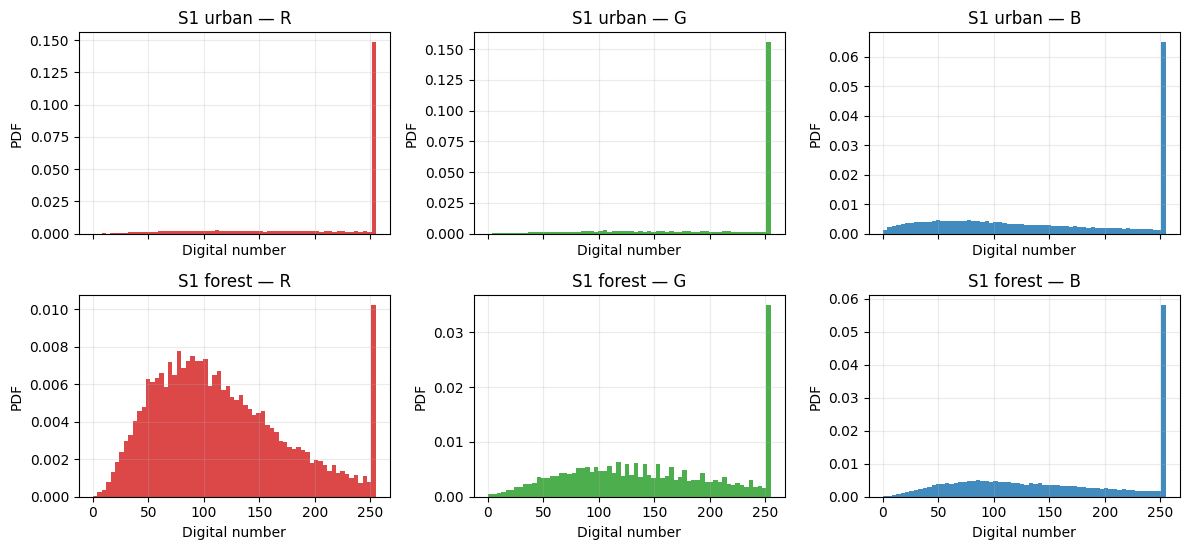

In [5]:
plot_channel_pdfs(
    [s1_urban, s1_forest],
    ['S1 urban', 'S1 forest']
)

In [6]:
# Compact numeric summary of each channel
def summarise(name, img):
    print(f'{name}')
    for i, ch in enumerate('RGB'):
        x = img[:, :, i].ravel().astype(float)
        print(f'  {ch}: mean={x.mean():5.1f}  std={x.std():5.1f}  '
              f'p5={np.percentile(x, 5):5.1f}  p95={np.percentile(x, 95):5.1f}')

summarise('S2 urban', s2_urban)
summarise('S2 forest', s2_forest)
summarise('S1 urban', s1_urban)
summarise('S1 forest', s1_forest)

S2 urban
  R: mean=114.2  std= 32.6  p5= 54.0  p95=165.0
  G: mean=114.1  std= 26.3  p5= 74.0  p95=159.0
  B: mean=101.7  std= 30.4  p5= 52.0  p95=152.0
S2 forest
  R: mean= 50.2  std= 15.3  p5= 37.0  p95= 83.0
  G: mean= 74.5  std=  9.8  p5= 63.0  p95= 96.0
  B: mean= 52.9  std=  7.5  p5= 45.0  p95= 66.0
S1 urban


  R: mean=206.8  std= 69.3  p5= 62.0  p95=255.0
  G: mean=211.3  std= 67.6  p5= 65.0  p95=255.0
  B: mean=145.6  std= 85.5  p5= 20.0  p95=255.0
S1 forest
  R: mean=115.7  std= 59.5  p5= 35.0  p95=242.0
  G: mean=145.8  std= 70.3  p5= 39.0  p95=255.0
  B: mean=153.6  std= 76.8  p5= 38.0  p95=255.0


### Observations — PDF of Sentinel data

**Sentinel-2 (optical)**
- The **urban** scene has a **wider, more multimodal** distribution: roofs, roads, shadows and vegetation occupy different brightness ranges, so the PDF spreads across many digital numbers and can show several peaks.
- The **forest** scene is more **homogeneous**: vegetation dominates, so the PDF is narrower and more concentrated (lower standard deviation in the numeric summary).

**Sentinel-1 (SAR)**
- SAR responses reflect surface roughness and dielectric properties, not reflected sunlight. In the Browser false-colour export the histograms are still broad, with a **grainy / heavy-tailed** look consistent with **speckle** noise.
- Urban SAR often shows stronger returns from buildings (double-bounce), while forest returns are more diffuse; both remain noisier than the optical PDFs.

**Optical vs radar**
- Optical PDFs mainly describe spectral reflectance of land-cover classes.
- SAR PDFs are shaped by geometry + speckle; they are less “clean” class-separable in a simple RGB export, but still useful as a statistical fingerprint of the scene.

## 2. Steganography — Manipulating the Two LSBs

We take the Sentinel-2 urban image, replace the **two least significant bits** of every pixel and every channel with a random value in $\{0,1,2,3\}$, then compare visual quality and PDFs.

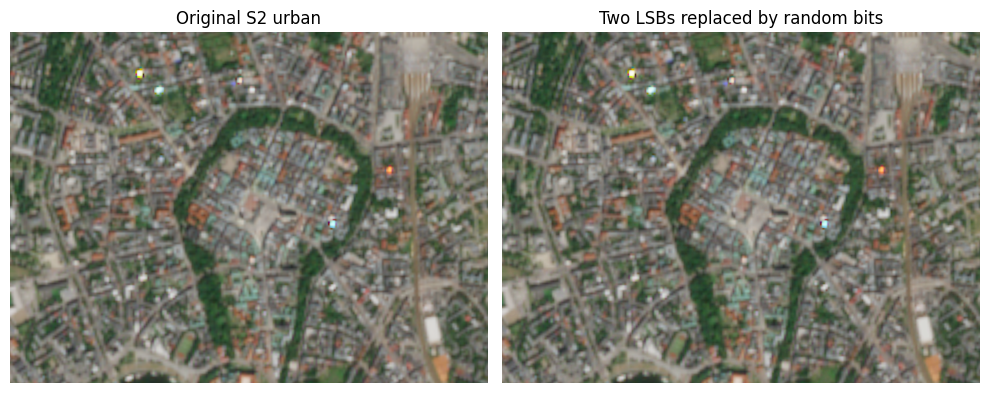

Max |original - manipulated|: 3
Fraction of changed pixels: 0.7501339548164945


In [7]:
# Work on an integer copy of the S2 urban image
original = s2_urban.copy().astype(np.uint8)

# Clear the two LSBs (AND with 252 = 11111100b), then OR in a random 2-bit value
random_bits = np.random.randint(0, 4, size=original.shape, dtype=np.uint8)
manipulated = (original & np.uint8(252)) | random_bits

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(original)
axes[0].set_title('Original S2 urban')
axes[0].axis('off')
axes[1].imshow(manipulated)
axes[1].set_title('Two LSBs replaced by random bits')
axes[1].axis('off')
plt.tight_layout()
plt.show()

# Max absolute difference is at most 3 DN — expected for 2-bit changes
print('Max |original - manipulated|:', np.max(np.abs(original.astype(int) - manipulated.astype(int))))
print('Fraction of changed pixels:', np.mean(original != manipulated))

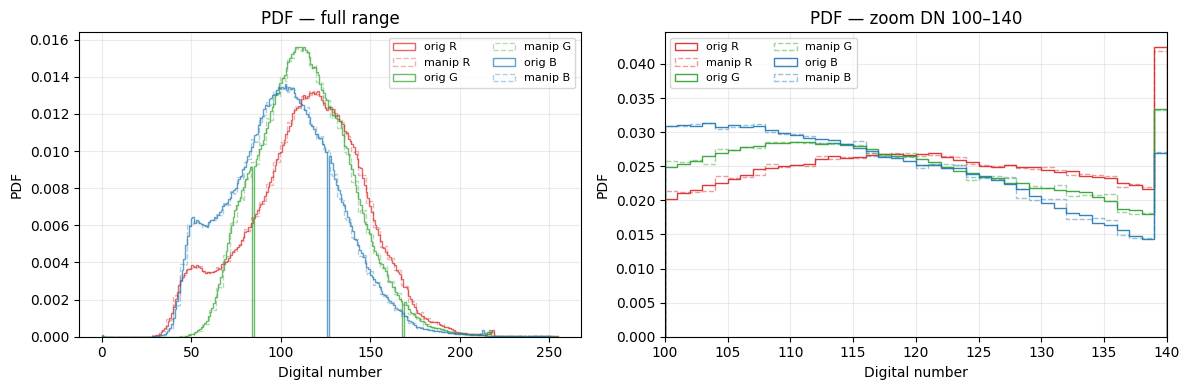

In [8]:
# Overlay PDFs: full range and a zoomed window where LSB structure is visible
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for c, color, name in zip(range(3), ('tab:red', 'tab:green', 'tab:blue'), 'RGB'):
    axes[0].hist(original[:, :, c].ravel(), bins=256, density=True,
                 histtype='step', color=color, alpha=0.7, label=f'orig {name}')
    axes[0].hist(manipulated[:, :, c].ravel(), bins=256, density=True,
                 histtype='step', color=color, alpha=0.35, linestyle='--',
                 label=f'manip {name}')

axes[0].set_title('PDF — full range')
axes[0].set_xlabel('Digital number')
axes[0].set_ylabel('PDF')
axes[0].legend(fontsize=8, ncol=2)
axes[0].grid(True, alpha=0.25)

# Zoom on a mid-grey window to see the artificial 4-level grouping
lo, hi = 100, 140
for c, color, name in zip(range(3), ('tab:red', 'tab:green', 'tab:blue'), 'RGB'):
    axes[1].hist(original[:, :, c].ravel(), bins=np.arange(lo, hi + 1), density=True,
                 histtype='step', color=color, alpha=0.9, label=f'orig {name}')
    axes[1].hist(manipulated[:, :, c].ravel(), bins=np.arange(lo, hi + 1), density=True,
                 histtype='step', color=color, alpha=0.45, linestyle='--',
                 label=f'manip {name}')

axes[1].set_xlim(lo, hi)
axes[1].set_title(f'PDF — zoom DN {lo}–{hi}')
axes[1].set_xlabel('Digital number')
axes[1].set_ylabel('PDF')
axes[1].legend(fontsize=8, ncol=2)
axes[1].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

### Does it affect visual quality?

**No.** Changing only the two LSBs alters each digital number by at most 3 (out of 0–255). Side-by-side, the original and manipulated images look the same to the human eye — the change is below typical perceptual sensitivity for 8-bit imagery.

### Can this be used to detect if a satellite image has been manipulated?

**Yes.** Even when the image looks identical, the **PDF / histogram changes**. Randomising the two LSBs reshapes the fine structure of the histogram (local “steps”, smoothing or periodic modulation every 4 grey levels). Statistical steganalysis can pick up such artefacts even when visual inspection cannot.

So: LSB embedding is a weak visual attack, but a detectable statistical one — useful as a simple integrity check for EO products.

## 3. Compressive Sensing — Sparse Recovery with $L_1$

Following the lab demo: a length-$N$ signal that is **sparse in the DCT domain** is randomly subsampled far below the Nyquist count. We recover it by minimising the $L_1$ norm of the DCT coefficients while fitting the known samples (soft-constrained form of the classic “$L_1$ magic” idea from the worksheet).

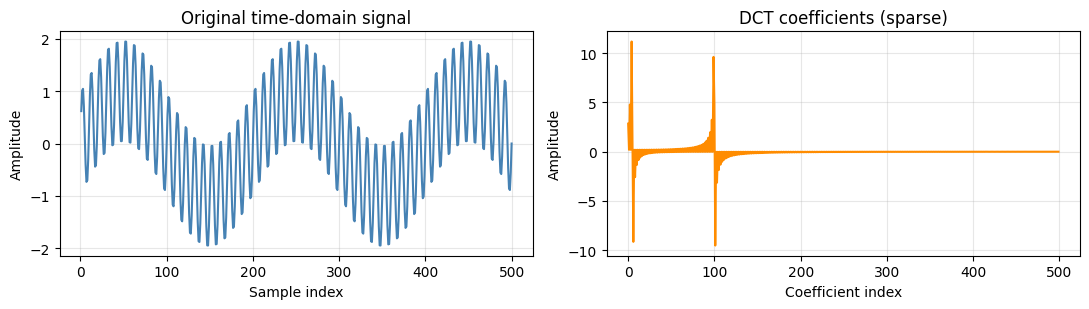

In [9]:
# Two-tone signal: sparse in DCT, not sparse in time
N = 500
t = np.arange(1, N + 1)
xx = np.sin(2 * np.pi * t / 10) + np.sin(2 * np.pi * t / 200)
XX_true = fftpack.dct(xx, norm='ortho')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].plot(t, xx, color='steelblue')
axes[0].set_title('Original time-domain signal')
axes[0].set_xlabel('Sample index')
axes[0].set_ylabel('Amplitude')
axes[0].grid(True, alpha=0.3)

axes[1].plot(XX_true, color='darkorange')
axes[1].set_title('DCT coefficients (sparse)')
axes[1].set_xlabel('Coefficient index')
axes[1].set_ylabel('Amplitude')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

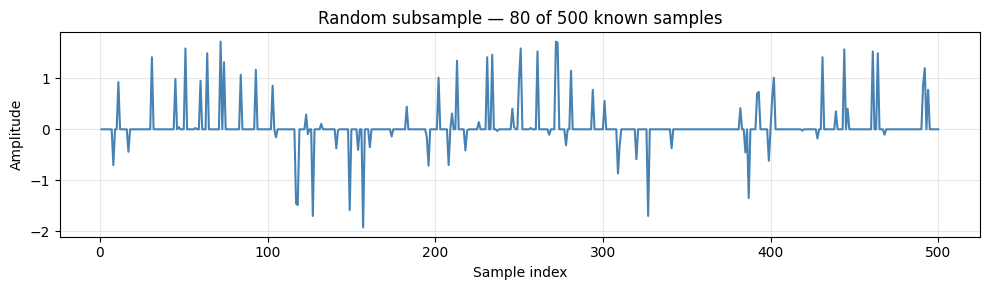

In [10]:
# Keep only n random samples (n << N; Nyquist for the fast tone would want ~100)
n = 80
idx = np.sort(np.random.choice(N, size=n, replace=False))
y = xx[idx]

sp = np.zeros(N)
sp[idx] = 1
xp = xx * sp

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t, xp, color='steelblue')
ax.set_title(f'Random subsample — {n} of {N} known samples')
ax.set_xlabel('Sample index')
ax.set_ylabel('Amplitude')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Optimiser success : False | STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT
Iterations        : 596
Correlation       : 0.957
RMSE              : 0.322


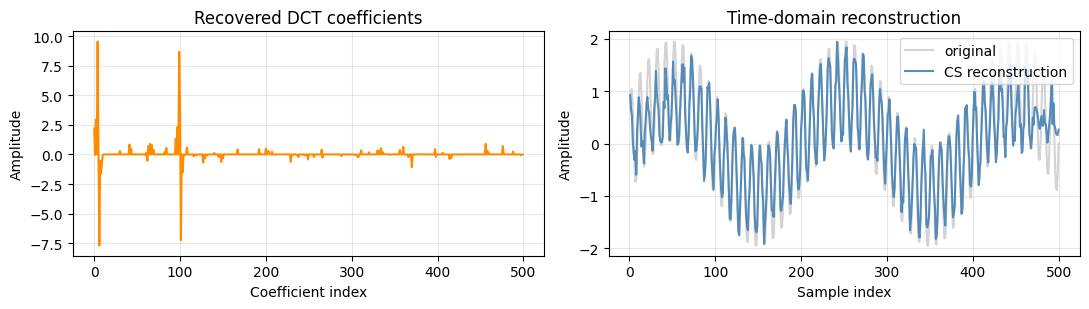

In [11]:
# L1 recovery: minimise ||XX||_1 + λ ||idct(XX)[idx] - y||_2^2
lam = 25.0

def cost_cs(XX):
    xd = fftpack.idct(XX, norm='ortho')
    return np.linalg.norm(XX, ord=1) + lam * np.sum((xd[idx] - y) ** 2)

CS = optimize.minimize(
    cost_cs,
    np.zeros(N),
    method='L-BFGS-B',
    options={'maxiter': 3000, 'maxfun': 300000, 'ftol': 1e-15, 'disp': False},
)

xrecon = fftpack.idct(CS.x, norm='ortho')
corr = np.corrcoef(xx, xrecon)[0, 1]
rmse = np.sqrt(np.mean((xx - xrecon) ** 2))

print('Optimiser success :', CS.success, '|', CS.message)
print('Iterations        :', CS.nit)
print('Correlation       :', round(corr, 3))
print('RMSE              :', round(rmse, 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].plot(CS.x, color='darkorange')
axes[0].set_title('Recovered DCT coefficients')
axes[0].set_xlabel('Coefficient index')
axes[0].set_ylabel('Amplitude')
axes[0].grid(True, alpha=0.3)

axes[1].plot(t, xx, color='lightgray', label='original')
axes[1].plot(t, xrecon, color='steelblue', alpha=0.9, label='CS reconstruction')
axes[1].set_title('Time-domain reconstruction')
axes[1].set_xlabel('Sample index')
axes[1].set_ylabel('Amplitude')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In this run the $L_1$ recovery already reaches a high correlation with the original two-tone signal (~0.96), even if the optimiser stops on an evaluation limit — the same practical situation described in the lab worksheet.

### Where may compressive sensing be useful in Earth Observation (EO)?

Satellites collect **huge volumes** of imagery (optical, SAR, hyperspectral) — often terabytes per day across a constellation — but the **downlink** from orbit to the ground station is narrow and intermittent. On-board storage is also limited.

If a scene (or a signal derived from it) is **sparse in a known basis** (DCT, wavelets, etc.), compressive sensing lets us:
- acquire or retain **fewer measurements** than classical Nyquist sampling suggests,
- still reconstruct the essential content by $L_1$ / sparse recovery,
- reduce on-board memory and free downlink capacity without throwing away the main information.

Concrete EO angles: sparse sampling of spectrometer bands, SAR raw-data reduction, rapid tasking of event-driven acquisitions, and any pipeline where the scientific content lives in a few coefficients rather than in every pixel. CS does not replace good sensor design, but it is a practical answer to the **data volume vs bandwidth** bottleneck in Earth Observation.

## Summary

1. **PDFs**: Urban optical scenes are spectrally more diverse (wider / multimodal histograms) than forest; SAR PDFs reflect structure plus speckle and differ clearly from optical reflectance histograms.
2. **Steganography**: Two-bit LSB replacement is **visually invisible** but **statistically visible** in the PDF — a simple manipulation detector for EO images.
3. **Compressive sensing**: Sparse signals can be recovered from random undersampling via $L_1$ optimisation; in EO this idea targets the downlink / storage bottleneck.

AI tools were applied for formatting and plotting results.